#Preâmbulo
---
Disponível em todas as aulas

In [ ]:
# principais
import pandas as pd
import numpy as np
import statsmodels.api as sm


#Gráficos
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# complementares
from google.colab import files #para importar arquivos
import warnings
warnings.filterwarnings('ignore') #para deixar de ver coisas inúteis
#from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf #importar os gráficos da função de autocorrelação e autocorrelação parcial
#from arch.unitroot import ADF, PhillipsPerron, KPSS, DFGLS, ZivotAndrews

#configurar gráficos

In [ ]:
!pip install arch
print('***PACOTE INSTALADO***')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 51.2 MB/s eta 0:00:00
***PACOTE INSTALADO***


In [ ]:
import arch
from arch.unitroot import ADF
from arch.unitroot import PhillipsPerron
from arch.unitroot import KPSS
from arch.unitroot import DFGLS
from arch.unitroot import ZivotAndrews

In [ ]:
!pip install pmdarima
print('***PACOTE INSTALADO***')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 28.1 MB/s eta 0:00:00
***PACOTE INSTALADO***


In [ ]:
import pmdarima as pm

In [ ]:
!pip install kapetanios-test

In [ ]:
from kapetanios_test import kapetanios_test

#Obtenção dos dados
---
Realizei aqui a organização das colunas e atribuição de um indexador para as datas. Os dados já foram obtidos com sazonalidade do próprio Banco Central, sendo necessário realizar o ajuste sazonal nas próximas etapas.

In [ ]:
#Importando dados da internet
url_ibcr_ne = 'https://api.bcb.gov.br/dados/serie/bcdata.sgs.25388/dados?formato=json'
ibcr_ne = pd.read_json(url_ibcr_ne)
ibcr_ne #para chamar e visualizar série

,data,valor
0,01/01/2003,68.14
1,01/02/2003,65.45
2,01/03/2003,67.53
3,01/04/2003,68.28
4,01/05/2003,69.20
...,...,...
274,01/11/2025,107.63
275,01/12/2025,108.84
276,01/01/2026,104.29
277,01/02/2026,106.62


#Tratamento e limpeza dos dados


In [ ]:
ibcr_ne = ibcr_ne.drop(columns = {'data'})
ibcr_ne

,valor
0,68.14
1,65.45
2,67.53
3,68.28
4,69.20
...,...
274,107.63
275,108.84
276,104.29
277,106.62


In [ ]:
datas = pd.date_range(start = "2003-01-01", end = "2026-03-28", freq = "MS")
ibcr_ne = ibcr_ne.set_index(datas)
ibcr_ne

,valor
2003-01-01,68.14
2003-02-01,65.45
2003-03-01,67.53
2003-04-01,68.28
2003-05-01,69.20
...,...
2025-11-01,107.63
2025-12-01,108.84
2026-01-01,104.29
2026-02-01,106.62


In [ ]:
ibcr_ne = ibcr_ne.loc["2003-01-01":"2016-08-31"]

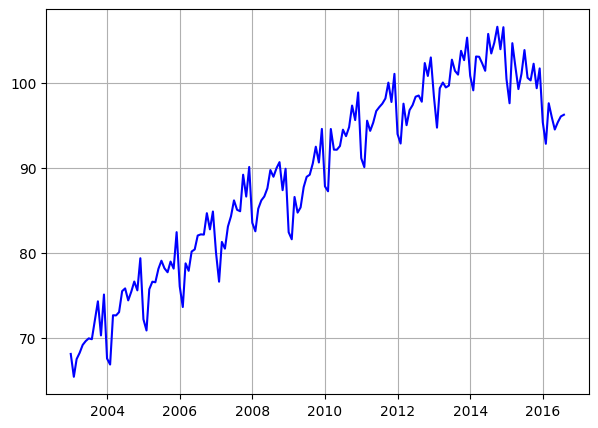

In [ ]:
plt.figure(figsize = (7,5))
plt.plot(ibcr_ne, color = "blue")
#plt.title('IBCR Nordeste - Sem ajuste sazonal')
plt.grid()
plt.show()

###Decomposição da série


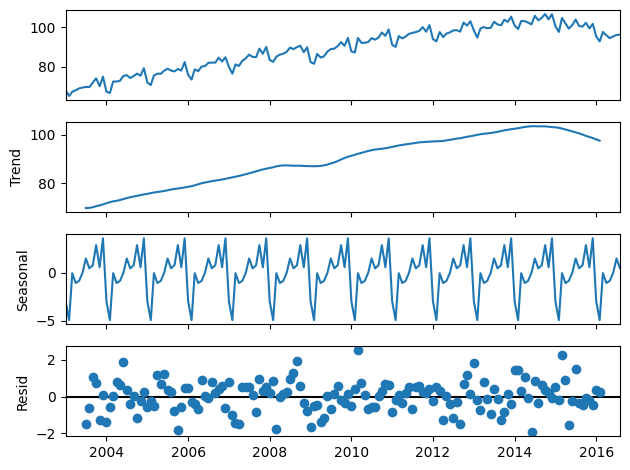

In [ ]:
decomposicao_ibcr_ne = sm.tsa.seasonal_decompose(ibcr_ne, model = "additive", period = 12) #sm para chamar o statsmodels. Tipos de modelos: aditivo ou multiplicativo. 4 períodos por ano(trimestral)
# é possível acessar o site do statsmodels para ver mais detalhes sobre as funções
decomposicao_ibcr_ne.plot()
plt.show()

In [ ]:
ibcr_ne_dessazonalizado = decomposicao_ibcr_ne.observed - decomposicao_ibcr_ne.seasonal
ibcr_ne_dessazonalizado

,0
2003-01-01,71.099738
2003-02-01,70.366597
2003-03-01,67.565155
2003-04-01,69.340849
2003-05-01,70.039773
...,...
2016-04-01,97.050849
2016-05-01,95.389773
2016-06-01,95.416509
2016-07-01,94.598424


#Visualizaçao gráfica


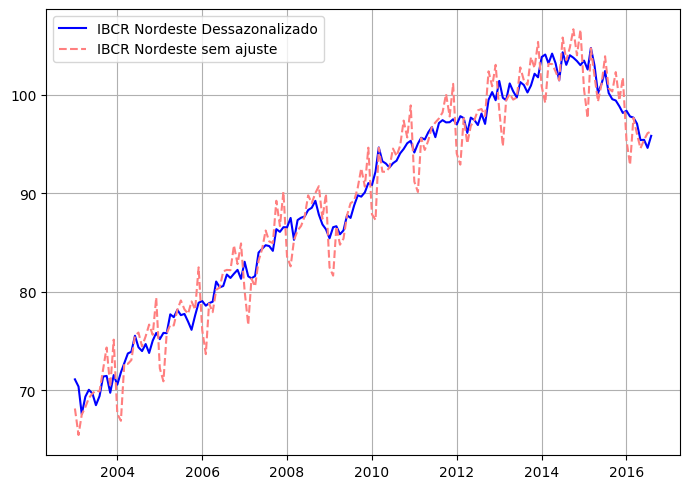

In [ ]:
plt.figure(figsize = (7, 5)) #tamanho da figura

plt.plot(ibcr_ne_dessazonalizado, color = "blue", label = "IBCR Nordeste Dessazonalizado") #para selecionar a varíavel que você quer plotar. Label para definir nome da variável
plt.plot(ibcr_ne, color = "#FF7F7F", label = "IBCR Nordeste sem ajuste", linestyle = "--") #para selecionar a varíavel que você quer plotar. Label para definir nome da variável

plt.legend() #MOSTRA A LEGENDA
plt.tight_layout() #ajustar tamanho
plt.grid(True) #adicionar linhas
#plt.title("IBCR Nordeste") #Para dar título ao gráfico
#
plt.show()

#Função de autocorrelação e autocorrelação parcial
---
Apresentação do gráfico das funções de autocorrelação e autocorrelação parcial para o série diferenciada. Vê-se que os problemas são solucionados em relação ao mesmo gráfico apresentado anteriormente

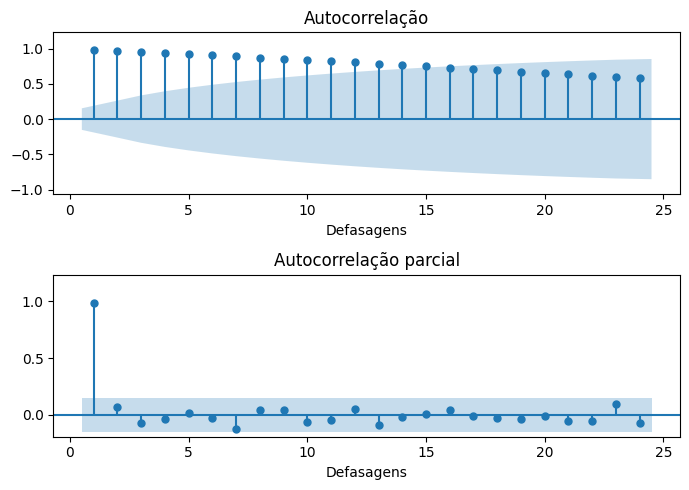

In [ ]:
fig, axes = plt.subplots(2,1, figsize = (7,5))
#
plot_acf(ibcr_ne_dessazonalizado, lags = 24, ax = axes[0], zero = False, auto_ylims = True, alpha = 0.05)
axes[0].set_title("Autocorrelação")
axes[0].set_xlabel('Defasagens')
#
plot_pacf(ibcr_ne_dessazonalizado, lags = 24, ax = axes[1], zero = False, auto_ylims = True, alpha = 0.05)
axes[1].set_title("Autocorrelação parcial")
axes[1].set_xlabel('Defasagens')
#
plt.tight_layout()
plt.show()

#Teste de raiz unitária e estacionaridade
---
Inicialmente a série não passou em nenhum teste de raiz unitária, sendo necessário diferenciar a série uma vez, logrando, assim, alcançar sucesso em todos os testes de estacionaridade.

##Definindo código para teste geral

In [ ]:
#definindo função para executar vários testes ao mesmo tempo
def teste_r_unitária(series, trend = 'c'):
  """
  Argumentos:
  1. Série que será testada;
  2. Tendência
  """
  print(f"---- Testes de Raiz Unitária ----\n")

  #Teste ADF
  adf_test = ADF (series, trend = trend)
  print(adf_test.summary())
  print(f"\n")

  #Teste KPSS
  kpss_test = KPSS (series, trend = trend)
  print(kpss_test.summary())
  print(f"\n")

  #Teste Phillips Perron
  pp_test = PhillipsPerron (series, trend = trend)
  print(pp_test.summary())
  print(f"\n")

  #Teste DFGLS
  dfgls_test = DFGLS (series, trend = trend)
  print(dfgls_test.summary())
  print(f"\n")

  #Teste Zivot-Andrews
  za_test = ZivotAndrews (series, trend = trend)
  print(za_test.summary())
  print(f"\n")

  k_auto = kapetanios_test(series,max_breaks=5,model='C',lag_selection='aic')
  print(k_auto)
  print(f"\n")

##Teste inicial

In [ ]:
teste_r_unitária(ibcr_ne_dessazonalizado, trend = 'ct')

---- Testes de Raiz Unitária ----

   Augmented Dickey-Fuller Results   
Test Statistic                  1.373
P-value                         1.000
Lags                                2
-------------------------------------

Trend: Constant and Linear Time Trend
Critical Values: -4.02 (1%), -3.44 (5%), -3.14 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


    KPSS Stationarity Test Results   
Test Statistic                  0.302
P-value                         0.002
Lags                                8
-------------------------------------

Trend: Constant and Linear Time Trend
Critical Values: 0.22 (1%), 0.15 (5%), 0.12 (10%)
Null Hypothesis: The process is weakly stationary.
Alternative Hypothesis: The process contains a unit root.


     Phillips-Perron Test (Z-tau)    
Test Statistic                 -0.301
P-value                         0.990
Lags                               14
------------------------------

##Teste após diferenciação

In [ ]:
diff_ibcr_ne = ibcr_ne_dessazonalizado.diff()
diff_ibcr_ne = diff_ibcr_ne.dropna()
diff_ibcr_ne

,None
2003-02-01,-0.733141
2003-03-01,-2.801442
2003-04-01,1.775694
2003-05-01,0.698924
2003-06-01,-0.383264
...,...
2016-04-01,-0.624306
2016-05-01,-1.661076
2016-06-01,0.026736
2016-07-01,-0.818085


In [ ]:
teste_r_unitária(diff_ibcr_ne, trend = 'ct')

---- Testes de Raiz Unitária ----

   Augmented Dickey-Fuller Results   
Test Statistic                 -8.396
P-value                         0.000
Lags                                2
-------------------------------------

Trend: Constant and Linear Time Trend
Critical Values: -4.02 (1%), -3.44 (5%), -3.14 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


    KPSS Stationarity Test Results   
Test Statistic                  0.071
P-value                         0.341
Lags                                0
-------------------------------------

Trend: Constant and Linear Time Trend
Critical Values: 0.22 (1%), 0.15 (5%), 0.12 (10%)
Null Hypothesis: The process is weakly stationary.
Alternative Hypothesis: The process contains a unit root.


     Phillips-Perron Test (Z-tau)    
Test Statistic                -17.445
P-value                         0.000
Lags                               14
------------------------------

In [ ]:
diff_ibcr_ne.head(128)

,None
2003-02-01,-0.733141
2003-03-01,-2.801442
2003-04-01,1.775694
2003-05-01,0.698924
2003-06-01,-0.383264
...,...
2013-05-01,-0.801076
2013-06-01,-0.623264
2013-07-01,1.561915
2013-08-01,-0.297788


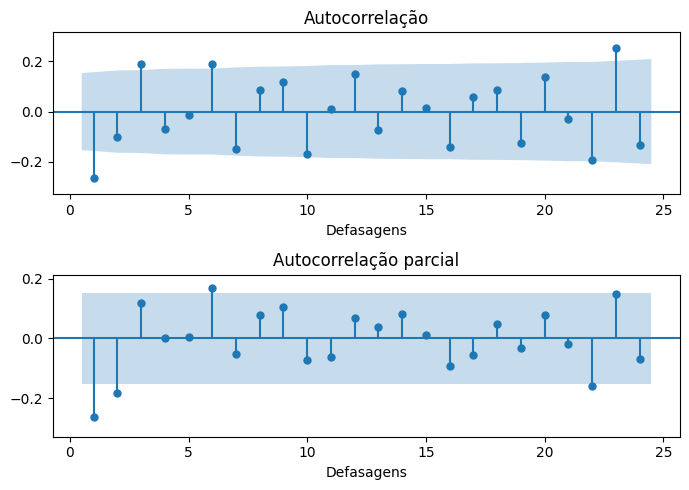

In [ ]:
fig, axes = plt.subplots(2,1, figsize = (7,5))
#
plot_acf(diff_ibcr_ne, lags = 24, ax = axes[0], zero = False, auto_ylims = True, alpha = 0.05)
axes[0].set_title("Autocorrelação")
axes[0].set_xlabel('Defasagens')
#
plot_pacf(diff_ibcr_ne, lags = 24, ax = axes[1], zero = False, auto_ylims = True, alpha = 0.05)
axes[1].set_title("Autocorrelação parcial")
axes[1].set_xlabel('Defasagens')
#
plt.tight_layout()
plt.show()

#Critério de seleção
---

- AIC: ARMA(2,3)
- BIC: ARMA(2,3)
- HQIC: ARMA(2,3)

In [ ]:
criterio_inf = sm.tsa.stattools.arma_order_select_ic(
    diff_ibcr_ne,
    max_ar = 5,
    max_ma = 4,
    ic = ['aic','bic', 'hqic'],
    trend = 'c'
)
criterio_inf

{'aic':             0           1           2           3           4
 0  494.449801  481.792741  483.788810  480.845232  482.841316
 1  484.690312  483.791200  484.355486  482.838325  484.836245
 2  480.494608  480.776864  475.759451  468.904335  483.102164
 3  479.945449  480.088340  481.644694  483.642860  470.803728
 4  481.934795  481.751572  483.931743  473.710987  472.891406
 5  483.919298  483.195556  484.889855  475.632856  475.226558,
 'bic':             0           1           2           3           4
 0  500.637302  491.073992  496.163811  496.313983  501.403817
 1  493.971563  496.166200  499.824237  501.400827  506.492496
 2  492.869608  496.245615  494.321952  490.560587  507.852166
 3  495.414200  498.650842  503.300945  508.392861  498.647480
 4  500.497296  503.407823  508.681744  501.554739  503.828908
 5  505.575549  507.945558  512.733607  506.570358  509.257810,
 'hqic':             0           1           2           3           4
 0  496.961859  485.560827  488

##Estimação do modelo
---
Todos os critérios de seleção apontaram um ARMA(2,3). Como a série deve ser diferenciada, o modelo testado será um ARIMA(2,1,3).


###Dummies de impulso sugeridas pelo Teste de Kapetanios

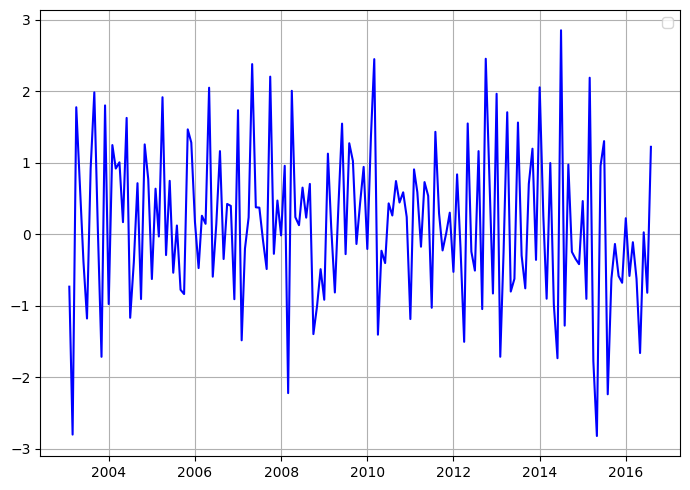

In [ ]:
plt.figure(figsize = (7,5)) #tamanho da figura

plt.plot(diff_ibcr_ne, color = "blue", label = "") #para selecionar a varíavel que você quer plotar. Label para definir nome da variável

plt.legend() #MOSTRA A LEGENDA
plt.tight_layout() #ajustar tamanho
plt.grid(True) #adicionar linhas
#plt.title("IBCR Nordeste - Primeira diferença") #Para dar título ao gráfico
#
plt.show()

##Sem dummy

In [ ]:
modelo_1 = sm.tsa.ARIMA(diff_ibcr_ne, order = (2,0,3), trend = 'ct')
modelo_1_estimado = modelo_1.fit()
print(modelo_1_estimado.summary())

                               SARIMAX Results                                
Dep. Variable:                   None   No. Observations:                  163
Model:                 ARIMA(2, 0, 3)   Log Likelihood                -229.076
Date:                Sun, 21 Jun 2026   AIC                            474.153
Time:                        17:28:40   BIC                            498.903
Sample:                    02-01-2003   HQIC                           484.201
                         - 08-01-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3701      0.117      3.154      0.002       0.140       0.600
x1            -0.0026      0.001     -2.129      0.033      -0.005      -0.000
ar.L1         -1.0981      0.098    -11.157      0.0

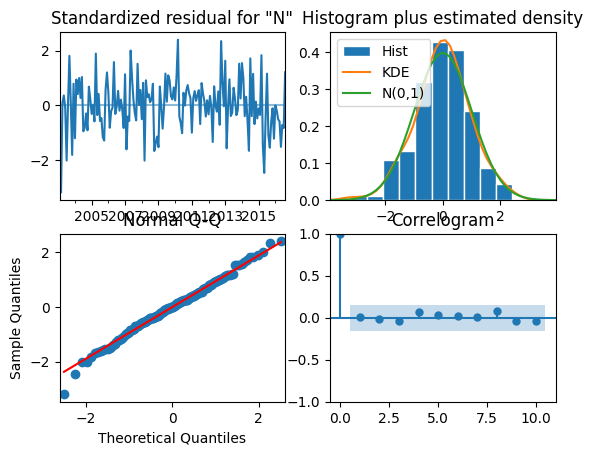

In [ ]:
modelo_1_estimado.plot_diagnostics()
plt.show();

In [ ]:
np.abs(modelo_1_estimado.maroots)

array([1.11358283, 1.11358283, 3.7435291 ])

In [ ]:
np.abs(modelo_1_estimado.arroots)

array([1.04576638, 1.04576638])

##Dummies para mandatos

In [ ]:
start_date_lula1 = '2003-01-01'
end_date_lula1 = '2006-12-31'

dummy_lula1 = ((ibcr_ne.index >= start_date_lula1) & (ibcr_ne.index <= end_date_lula1)).astype(int)
dummy_lula1 = pd.Series(dummy_lula1, index=ibcr_ne.index, name='dummy_lula1')

In [ ]:
start_date_lula2 = '2007-01-01'
end_date_lula2 = '2010-12-31'

dummy_lula2 = ((ibcr_ne.index >= start_date_lula2) & (ibcr_ne.index <= end_date_lula2)).astype(int)
dummy_lula2 = pd.Series(dummy_lula2, index=ibcr_ne.index, name='dummy_lula2')

In [ ]:
start_date_dilma1 = '2011-01-01'
end_date_dilma1 = '2014-12-31'

dummy_dilma1 = ((ibcr_ne.index >= start_date_dilma1) & (ibcr_ne.index <= end_date_dilma1)).astype(int)
dummy_dilma1 = pd.Series(dummy_dilma1, index=ibcr_ne.index, name='dummy_dilma1')

In [ ]:
start_date_dilma2 = '2015-01-01'
end_date_dilma2 = '2016-08-31'

dummy_dilma2 = ((ibcr_ne.index >= start_date_dilma2) & (ibcr_ne.index <= end_date_dilma2)).astype(int)
dummy_dilma2 = pd.Series(dummy_dilma2, index=ibcr_ne.index, name='dummy_dilma2')

In [ ]:
quebra1 = '2007-03-01'

dummy_quebra1 = ((ibcr_ne.index == quebra1)).astype(int)
dummy_quebra1 = pd.Series(dummy_quebra1, index=ibcr_ne.index, name='dummy_quebra1')

In [ ]:
quebra2 = '2009-04-01'

dummy_quebra2 = ((ibcr_ne.index == quebra2)).astype(int)
dummy_quebra2 = pd.Series(dummy_quebra2, index=ibcr_ne.index, name='dummy_quebra2')

In [ ]:
quebra3 = '2013-09-01'

dummy_quebra3 = ((ibcr_ne.index == quebra3)).astype(int)
dummy_quebra3 = pd.Series(dummy_quebra3, index=ibcr_ne.index, name='dummy_quebra3')

In [ ]:
X = pd.DataFrame({
    'dummy_lula1': dummy_lula1,
    'dummy_lula2': dummy_lula2,
    'dummy_dilma1': dummy_dilma1,
    'dummy_dilma2': dummy_dilma2,
    #'dummy_quebra1': dummy_quebra1,
    #'dummy_quebra2': dummy_quebra2,
    #'dummy_quebra3': dummy_quebra3
    })

modelo_dummy = sm.tsa.ARIMA(diff_ibcr_ne, order = (2,0,3), exog = X.loc[diff_ibcr_ne.index], trend = 'ct')
modelo_dummy_est = modelo_dummy.fit()
print(modelo_dummy_est.summary())

                               SARIMAX Results                                
Dep. Variable:                   None   No. Observations:                  163
Model:                 ARIMA(2, 0, 3)   Log Likelihood                -223.865
Date:                Sun, 21 Jun 2026   AIC                            471.731
Time:                        17:28:47   BIC                            508.856
Sample:                    02-01-2003   HQIC                           486.803
                         - 08-01-2016                                         
Covariance Type:                  opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.0124      0.268     -0.046      0.963      -0.538       0.513
drift            0.0009      0.004      0.242      0.808      -0.006       0.008
dummy_lula1      0.2313      0.207      1.12

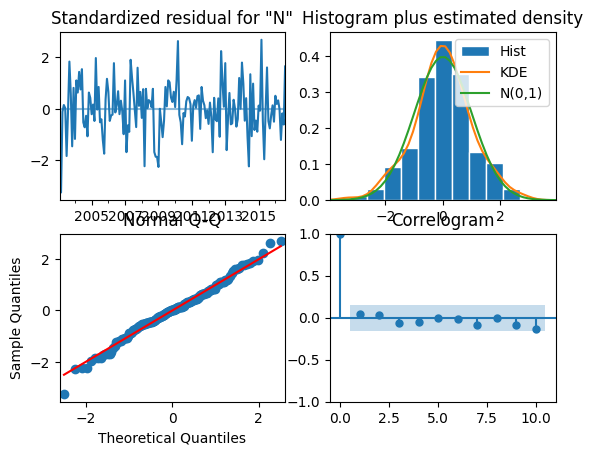

In [ ]:
modelo_dummy_est.plot_diagnostics()
plt.show();

In [ ]:
np.abs(modelo_dummy_est.arroots)

array([1.12176108, 1.12176108])

In [ ]:
np.abs(modelo_dummy_est.maroots)

array([1.17287784, 1.17287784, 2.00849077])